# SAXS background check, set aside for the final

Removed from `project11.ipynb` on 2026-11-21 to keep the draft short. To restore, add these lines to the Parameters cell and copy the three cells below back under A3:

```python
SAXS_RAW_FILES = {"01": "data/nPSize1.dat", "10": "data/nPSize10.dat"}   # q (nm^-1), I and I std (cm^-1), as measured
SAXS_SUBTRACTED_FILES = {"01": "data/nPSize1_wo_background.dat",          # same, with the water + capillary
                         "10": "data/nPSize10_wo_background.dat"}         # background removed by the SAXS group
```

#### Raw or background-subtracted SAXS curve

Each material has a raw SAXS curve and one with the solvent and capillary background removed by the SAXS group. This cell overlays the two (top) and plots their difference, the removed background (bottom), to decide which curve to fit and up to what q. Expect the curves to agree at low q and separate at high q, where the particle signal falls toward the background.

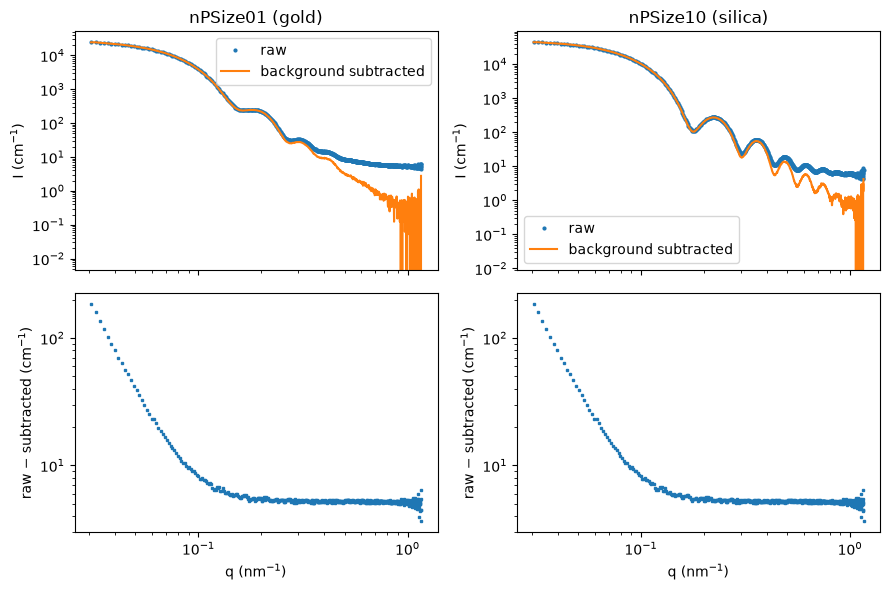

In [20]:
fig, axes = plt.subplots(2, 2, sharex=True, figsize=(9, 6))
for col, material in enumerate(MATERIALS):
    raw = np.loadtxt(SAXS_RAW_FILES[material], comments="#")          # columns: q (nm^-1), I (cm^-1), I std (cm^-1)
    subtracted = np.loadtxt(SAXS_SUBTRACTED_FILES[material], comments="#")
    if not np.allclose(raw[:, 0], subtracted[:, 0]):
        raise ValueError(f"nPSize{material}: raw and subtracted curves have different q grids")
    q_nm = raw[:, 0]                                                     # nm^-1
    background_cm = raw[:, 1] - subtracted[:, 1]                         # cm^-1

    ax = axes[0, col]
    ax.loglog(q_nm, raw[:, 1], "o", markersize=2, label="raw")
    ax.loglog(q_nm, subtracted[:, 1], "-", label="background subtracted")
    ax.set_title(f"nPSize{material} ({MATERIAL_NAMES[material]})")
    ax.set_ylabel("I (cm$^{-1}$)")
    ax.legend()

    ax = axes[1, col]
    ax.loglog(q_nm, background_cm, "s", markersize=2)
    ax.set_xlabel("q (nm$^{-1}$)")
    ax.set_ylabel("raw − subtracted (cm$^{-1}$)")
fig.tight_layout()

*Your one-sentence description of the figure, with the numbers.*